In [2]:

# CELL 1 — INSTALLATION AND CONFIGURATION
%pip -q install "google-auth==2.49.0" "google-genai>=2.12.1,<3" pymupdf

import re
import json
import time
import hashlib
from pathlib import Path
from getpass import getpass

import pymupdf as fitz
from google import genai
from google.genai import types
from google.colab import userdata

# Configuration
PDF_PATH = Path("/content/Latvia.pdf")
OUTPUT_DIR = Path("/content/latvia_task1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL = "gemini-3.5-flash-lite"
CHUNK_SIZE = 400
CHUNK_OVERLAP = 50

if not PDF_PATH.exists():
    raise FileNotFoundError("Latvia.pdf not found in Colab.")

# Read API key securely
api_key = None

for secret_name in ("CreatingAPI", "GEMINI_API_KEY"):
    try:
        api_key = userdata.get(secret_name)
        if api_key:
            break
    except Exception:
        continue

if not api_key:
    api_key = getpass("Enter Gemini API key: ").strip()

if not api_key:
    raise ValueError("Gemini API key is required.")

client = genai.Client(api_key=api_key)

# JSON utilities
def save_json(filename, data):
    (OUTPUT_DIR / filename).write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

def load_json(filename, default=None):
    path = OUTPUT_DIR / filename
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else default

# Lightweight LLM generation
def generate(prompt, max_tokens=600, attempts=3):
    for attempt in range(attempts):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    max_output_tokens=max_tokens
                )
            )

            result = (response.text or "").strip()

            if not result:
                raise ValueError("Empty model response.")

            return result

        except Exception as error:
            if attempt == attempts - 1:
                raise RuntimeError(f"Gemini API failed: {error}") from error
            time.sleep(2 ** attempt)

print("=" * 45)
print("TASK 1 — LATVIA IMF 2026")
print("=" * 45)
print("PDF:", PDF_PATH.name)
print("Model:", MODEL)
print("API key: Loaded")
print("Configuration: Successful")


TASK 1 — LATVIA IMF 2026
PDF: Latvia.pdf
Model: gemini-3.5-flash-lite
API key: Loaded
Configuration: Successful


In [3]:

# CELL 2 — PDF PROCESSING AND TOKEN-AWARE CHUNKING

%pip -q install tiktoken

import tiktoken

# 1. Extract and clean PDF text
def clean_text(text):
    """Remove PDF formatting noise while preserving financial data."""

    text = text.replace("\u00ad", "")
    text = re.sub(r"(?<=\w)-\s*\n(?=\w)", "", text)

    lines = []

    for line in text.splitlines():
        line = line.strip()

        if not line:
            continue

        # Remove repeated headers, footers and page numbers
        if re.fullmatch(r"\d{1,3}", line):
            continue

        if line.upper() == "REPUBLIC OF LATVIA":
            continue

        if re.fullmatch(
            r"(?:\d+\s+)?INTERNATIONAL MONETARY FUND(?:\s+\d+)?",
            line,
            re.IGNORECASE
        ):
            continue

        if "Not for Redistribution" in line:
            continue

        lines.append(line)

    return re.sub(r"\s+", " ", " ".join(lines)).strip()


with fitz.open(PDF_PATH) as document:
    pages = [
        {
            "page": i + 1,
            "text": clean_text(page.get_text("text", sort=True))
        }
        for i, page in enumerate(document)
    ]

full_text = "\n\n".join(
    f"[PDF PAGE {p['page']}]\n{p['text']}"
    for p in pages
)

(OUTPUT_DIR / "cleaned_text.txt").write_text(
    full_text, encoding="utf-8"
)

# 2. Fast local token-aware chunking
# cl100k_base provides approximate, not Gemini-native, token counts.
tokenizer = tiktoken.get_encoding("cl100k_base")

def create_chunks(pages, chunk_size=400, overlap=50):
    """Create overlapping chunks with PDF page references."""

    if not 0 <= overlap < chunk_size:
        raise ValueError("Overlap must be smaller than chunk size.")

    chunks = []
    step = chunk_size - overlap

    for page in pages:
        tokens = tokenizer.encode(page["text"])

        for start in range(0, len(tokens), step):
            piece = tokens[start:start + chunk_size]

            if not piece:
                break

            chunks.append({
                "chunk_id": len(chunks) + 1,
                "page": page["page"],
                "tokens": len(piece),
                "text": tokenizer.decode(piece)
            })

            if start + chunk_size >= len(tokens):
                break

    return chunks


chunks = create_chunks(
    pages,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
)

assert pages and chunks, "PDF extraction or chunking failed."

# 3. Save reusable outputs
save_json("chunks.json", chunks)

# 4. Display results
print("=" * 45)
print("TASK 1 — PDF PROCESSING RESULTS")
print("=" * 45)
print("Country            : Latvia")
print("PDF pages          :", len(pages))
print("Cleaned characters :", len(full_text))
print("Total chunks       :", len(chunks))
print("Target chunk size  :", CHUNK_SIZE)
print("Token overlap      :", CHUNK_OVERLAP)
print("PDF extraction     : Successful")
print("Text cleaning      : Completed")
print("Chunking           : Completed")
print("JSON saved         : chunks.json")
print("=" * 45)


TASK 1 — PDF PROCESSING RESULTS
Country            : Latvia
PDF pages          : 68
Cleaned characters : 166323
Total chunks       : 153
Target chunk size  : 400
Token overlap      : 50
PDF extraction     : Successful
Text cleaning      : Completed
Chunking           : Completed
JSON saved         : chunks.json


In [4]:

# CELL 3 — SECTION IDENTIFICATION AND SUMMARISATION

# Section headings and starting PDF pages (verified against Latvia.pdf)
section_info = [
    ("Context", 10, "CONTEXT"),
    ("Recent Developments", 11, "RECENT DEVELOPMENTS"),
    ("Outlook and Risks", 15, "OUTLOOK AND RISKS"),
    ("Managing Fiscal Pressures", 18, "A. Managing Fiscal Pressures"),
    ("Financial Sector Resilience", 25, "B. Strengthening Financial Sector Resilience"),
    ("Investment and Productivity", 26, "C. Policies to Boost Investment and Productivity"),
    ("Contingent Policy Responses", 31, "D. Contingent Policy Responses to Adverse Shocks"),
    ("Staff Appraisal", 32, "STAFF APPRAISAL"),
    ("Risk Assessment Matrix", 49, "Annex I. Risk Assessment Matrix"),
    ("External Sector Assessment", 51, "Annex II. External Sector Assessment"),
    ("Sovereign Risk and Debt Sustainability", 53, "Annex III. Sovereign Risk and Debt Sustainability Analysis"),
    ("Data Issues", 60, "Annex IV. Data Issues"),
    ("Past IMF Policy Recommendations", 63, "Annex V. Past IMF Policy Recommendations")
]

# Locate exact section boundaries within the PDF.
positions = []

for title, page_no, heading in section_info:
    match = re.search(
        re.escape(heading),
        pages[page_no - 1]["text"],
        re.IGNORECASE
    )

    if not match:
        raise ValueError(f"Section heading not found: {title}")

    positions.append((title, page_no, match.start()))

sections = {}

for i, (title, start_page, start_pos) in enumerate(positions):
    if i + 1 < len(positions):
        _, end_page, end_pos = positions[i + 1]
    else:
        end_page, end_pos = 66, 0

    # Exclude the figures and tables following Staff Appraisal.
    if title == "Staff Appraisal":
        end_page, end_pos = 35, 0

    content = []

    for page_no in range(start_page, end_page + 1):
        text = pages[page_no - 1]["text"]
        left = start_pos if page_no == start_page else 0
        right = end_pos if page_no == end_page else len(text)

        if left < right:
            content.append(f"[PDF page {page_no}] {text[left:right]}")

    sections[title] = "\n".join(content)

# Generate concise, source-grounded summaries.
section_summaries = load_json("section_summaries.json", {})

for title, source in sections.items():
    source_hash = hashlib.sha256(
        (MODEL + source).encode("utf-8")
    ).hexdigest()

    cached = section_summaries.get(title, {})

    if isinstance(cached, dict) and cached.get("source_hash") == source_hash:
        print(f"Cached: {title}")
        continue

    prompt = f"""
Summarise this section of the 2026 IMF Latvia Staff Report.

Section: {title}

Instructions:
- Write one clear academic paragraph of 60–85 words.
- Use only the provided IMF source text.
- Preserve important figures, dates and economic findings.
- Identify financial risks and policy implications.
- Distinguish historical facts from forecasts.
- Do not invent information or add unnecessary wording.

SOURCE:
{source}
"""

    summary = generate(prompt, max_tokens=350)

    # Enforce the assignment's strict word limit.
    if len(summary.split()) >= 100:
        summary = generate(
            "Rewrite this summary in 70–85 words, preserving its "
            "financial facts and meaning:\n" + summary,
            max_tokens=300
        )

    if not summary.strip() or len(summary.split()) >= 100:
        raise ValueError(f"Invalid summary length: {title}")

    section_summaries[title] = {
        "summary": summary.strip(),
        "word_count": len(summary.split()),
        "source_hash": source_hash
    }

    save_json("section_summaries.json", section_summaries)
    print(f"Completed: {title} ({len(summary.split())} words)")

print("\n" + "=" * 45)
print("TASK 1 — SECTION SUMMARISATION")
print("=" * 45)
print("Sections identified :", len(sections))
print("Summaries saved     :", len(section_summaries))
print("Model               :", MODEL)
print("Output              : section_summaries.json")


Completed: Context (78 words)
Completed: Recent Developments (86 words)
Completed: Outlook and Risks (80 words)
Completed: Managing Fiscal Pressures (75 words)
Completed: Financial Sector Resilience (72 words)
Completed: Investment and Productivity (74 words)
Completed: Contingent Policy Responses (82 words)
Completed: Staff Appraisal (81 words)
Completed: Risk Assessment Matrix (77 words)
Completed: External Sector Assessment (76 words)
Completed: Sovereign Risk and Debt Sustainability (76 words)
Completed: Data Issues (82 words)
Completed: Past IMF Policy Recommendations (76 words)

TASK 1 — SECTION SUMMARISATION
Sections identified : 13
Summaries saved     : 13
Model               : gemini-3.5-flash-lite
Output              : section_summaries.json


In [5]:

# CELL 4 — EXECUTIVE SUMMARY AND LLM EVALUATION

# 1. Prepare source evidence from the original IMF report
source_pages = [6, 7, 15, 16, 32, 33, 34]

source = "\n\n".join(
    f"[PDF Page {n}]\n{pages[n-1]['text']}"
    for n in source_pages
)

section_notes = "\n".join(
    f"{title}: {data['summary']}"
    for title, data in section_summaries.items()
)

source_hash = hashlib.sha256(
    (MODEL + source + section_notes).encode()
).hexdigest()

# 2. Generate the executive summary
executive = load_json("executive_summary.json", {})

if executive.get("source_hash") != source_hash:

    prompt = f"""
You are an IMF financial research analyst.

Prepare 7 concise executive-summary bullet points
for Latvia's 2026 IMF Article IV Consultation.

Cover:
1. Economic growth and outlook
2. Inflation and price pressures
3. Banking stability and credit risks
4. Fiscal balance and sovereign debt
5. Labour market and productivity
6. External and systemic vulnerabilities
7. Key IMF policy recommendations

Rules:
- Use only the supplied IMF evidence.
- Preserve important figures, percentages and years.
- Distinguish observed results from forecasts.
- Do not invent or assume financial information.
- Write clearly and professionally.

ORIGINAL IMF EVIDENCE:
{source}

SECTION SUMMARIES:
{section_notes}
"""

    executive = {
        "country": "Latvia",
        "report_year": 2026,
        "model": MODEL,
        "summary": generate(prompt, max_tokens=850),
        "source_hash": source_hash
    }

    save_json("executive_summary.json", executive)

print("EXECUTIVE SUMMARY")
print("-" * 50)
print(executive["summary"])

# 3. Evaluate against original IMF evidence
evaluation = load_json("summary_evaluation.json", {})

if evaluation.get("source_hash") != source_hash:

    judge_prompt = f"""
Act as a critical financial-analysis evaluator.

Compare the AI-generated executive summary with the
original IMF evidence.

Score each criterion from 1 to 5:
- factual_accuracy
- completeness
- consistency
- financial_relevance

Evaluate numerical accuracy, missing information,
unsupported claims and correct interpretation.

Do not automatically give high scores.
If the provided evidence is insufficient to verify
a claim, identify it as unverified.

Return a valid JSON object with exactly these fields:
"factual_accuracy": integer,
"completeness": integer,
"consistency": integer,
"financial_relevance": integer,
"unsupported_claims": array of strings,
"missing_findings": array of strings,
"overall_assessment": string

Use PDF page references when identifying errors.
Keep explanations short and evidence-based.

ORIGINAL IMF EVIDENCE:
{source}

SUMMARY TO EVALUATE:
{executive['summary']}
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=judge_prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=1200,
            response_mime_type="application/json"
        )
    )

    evaluation = json.loads(response.text)
    evaluation["source_hash"] = source_hash

    save_json("summary_evaluation.json", evaluation)

# 4. Display evaluation scores
criteria = [
    "factual_accuracy",
    "completeness",
    "consistency",
    "financial_relevance"
]

scores = [evaluation[key] for key in criteria]
average_score = sum(scores) / len(scores)

print("\nLLM-AS-A-JUDGE RESULTS")
print("-" * 50)

for key in criteria:
    print(f"{key.replace('_', ' ').title():22}: {evaluation[key]}/5")

print(f"\nAverage Judge Score: {average_score:.2f}/5")
print("\nAssessment:", evaluation["overall_assessment"])

print("\nSaved: executive_summary.json")
print("Saved: summary_evaluation.json")


EXECUTIVE SUMMARY
--------------------------------------------------
Here are 7 concise executive-summary bullet points for Latvia's 2026 IMF Article IV Consultation, based strictly on the provided IMF evidence:

* **1. Economic growth and outlook:** Following observed real GDP growth of 2.1 percent in 2025, annual growth is projected to decline to 1.8 percent in 2026 and recover slightly to 1.9 percent in 2027, constrained by the war in the Middle East and global trade tensions, before stabilizing around 2 percent over the medium term.
* **2. Inflation and price pressures:** Headline inflation, observed at 3.8 percent in 2025, is forecast to reach 4.0 percent in 2026 and 3.0 percent in 2027 driven by persistent energy and commodity supply disruptions, while core inflation is expected to remain elevated at 3.5 percent in 2026.
* **3. Banking stability and credit risks:** Latvia’s financial sector remains resilient with banks maintaining strong capital and liquidity buffers in 2025—incl

In [6]:

# CELL 5 — TASK 1 VALIDATION AND RESULTS

# 1. Validate PDF processing and chunking
assert len(pages) == 68, "PDF page count is incorrect."
assert chunks, "No text chunks found."
assert all(
    0 < chunk["tokens"] <= CHUNK_SIZE
    for chunk in chunks
), "Invalid chunk size."

# 2. Validate section summaries
assert len(section_summaries) == len(sections) == 13, \
    "Some IMF sections are missing."

word_counts = {
    title: len(data["summary"].split())
    for title, data in section_summaries.items()
}

assert all(0 < count < 100 for count in word_counts.values()), \
    "Section summary is empty or exceeds the 99-word limit."

# 3. Validate executive summary and judge scores
assert executive["summary"].strip(), "Executive summary is missing."

criteria = [
    "factual_accuracy",
    "completeness",
    "consistency",
    "financial_relevance"
]

assert all(
    type(evaluation.get(key)) is int
    and 1 <= evaluation[key] <= 5
    for key in criteria
), "Invalid evaluation scores."

assert evaluation["source_hash"] == executive["source_hash"], \
    "Evaluation does not match the executive summary."

average_score = round(
    sum(evaluation[key] for key in criteria) / len(criteria),
    2
)

# 4. Save consolidated Task 1 results
results = {
    "country": "Latvia",
    "report_year": 2026,
    "model": MODEL,
    "pdf_pages": len(pages),
    "total_chunks": len(chunks),
    "sections_summarised": len(section_summaries),
    "section_word_counts": word_counts,
    "section_summaries": section_summaries,
    "executive_summary": executive["summary"],
    "judge_scores": {
        key: evaluation[key] for key in criteria
    },
    "average_judge_score": average_score,
    "evaluation_details": evaluation
}

save_json("task1_results.json", results)

# 5. Display execution results
print("=" * 48)
print("TASK 1 — EXECUTION AND VALIDATION RESULTS")
print("=" * 48)
print(f"PDF Pages          : {len(pages)}")
print(f"Text Chunks        : {len(chunks)}")
print(f"Section Summaries  : {len(section_summaries)}")
print("Summary Word Limit : Passed")
print("Executive Summary  : Generated")

print("\nLLM-AS-A-JUDGE SCORES")
for key in criteria:
    print(f"{key.replace('_', ' ').title():22}: {evaluation[key]}/5")

print(f"\nAverage Judge Score: {average_score}/5")

print("\nSAVED OUTPUT FILES")
for file in sorted(OUTPUT_DIR.iterdir()):
    print(" -", file.name)

print("\nTask 1 validation checks passed.")
print("Results saved to:", OUTPUT_DIR)


TASK 1 — EXECUTION AND VALIDATION RESULTS
PDF Pages          : 68
Text Chunks        : 153
Section Summaries  : 13
Summary Word Limit : Passed
Executive Summary  : Generated

LLM-AS-A-JUDGE SCORES
Factual Accuracy      : 5/5
Completeness          : 5/5
Consistency           : 5/5
Financial Relevance   : 5/5

Average Judge Score: 5.0/5

SAVED OUTPUT FILES
 - chunks.json
 - cleaned_text.txt
 - executive_summary.json
 - section_summaries.json
 - summary_evaluation.json
 - task1_results.json

Task 1 validation checks passed.
Results saved to: /content/latvia_task1


In [7]:

# CELL 6 — FINANCIAL THEME EXTRACTION

# Seven themes required by the assignment
themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bHICP\b",
        r"\b(?:food|energy|consumer) prices?\b",
        r"\bprice pressures?\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bcredit growth\b",
        r"\blending rates?\b", r"\bloan growth\b",
        r"\bcredit conditions?\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bhouse prices?\b", r"\bmortgages?\b",
        r"\bproperty (?:prices?|market|tax)\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbanking sector\b", r"\bcapital adequacy\b",
        r"\b(?:CET1|tier 1)\b", r"\bliquidity\b",
        r"\bnon.performing loans?\b", r"\bNPLs?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bgovernment debt\b",
        r"\bsovereign (?:debt|risk)\b",
        r"\bdebt sustainability\b",
        r"\bfiscal (?:deficit|balance|consolidation)\b"
    ],
    "Labor Market Dynamics": [
        r"\bunemployment\b", r"\bemployment\b",
        r"\blabou?r (?:market|force|productivity|mobility)\b",
        r"\bwage growth\b", r"\bskill mismatches?\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b", r"\bsystemic risks?\b",
        r"\bmacroprudential\b", r"\bnonbank lending\b",
        r"\bfinancial vulnerabilities\b",
        r"\bfinancial sector risks?\b"
    ]
}

# Scan the Staff Report, excluding the separate press release
report_pages = pages[6:]
theme_results = []

for theme, keywords in themes.items():
    pattern = re.compile("|".join(keywords), re.IGNORECASE)

    counts = [
        (page["page"], len(pattern.findall(page["text"])))
        for page in report_pages
    ]

    theme_results.append({
        "theme": theme,
        "mentions": sum(count for _, count in counts),
        "pages_with_mentions": sum(count > 0 for _, count in counts)
    })

# Calculate thematic distribution
total_mentions = sum(item["mentions"] for item in theme_results)

for item in theme_results:
    item["percentage"] = round(
        100 * item["mentions"] / total_mentions, 2
    ) if total_mentions else 0.0

# Save machine-readable results
save_json("thematic_counts.json", {
    "country": "Latvia",
    "report_year": 2026,
    "method": "Case-insensitive keyword and phrase frequency",
    "total_mentions": total_mentions,
    "themes": theme_results
})

# Display results
print("TASK 2 — FINANCIAL THEME DISTRIBUTION")
print("-" * 65)
print(f"{'Financial Theme':35} {'Mentions':>10} {'Share':>10}")

for item in theme_results:
    print(
        f"{item['theme']:35} "
        f"{item['mentions']:>10} "
        f"{item['percentage']:>9.2f}%"
    )

print("-" * 65)
print("Total mentions:", total_mentions)
print("Saved: thematic_counts.json")


TASK 2 — FINANCIAL THEME DISTRIBUTION
-----------------------------------------------------------------
Financial Theme                       Mentions      Share
Inflation & Prices                          95     23.93%
Interest Rates & Credit                     27      6.80%
Housing & Real Estate                       55     13.85%
Banking Capital & Liquidity                 25      6.30%
Sovereign Debt                              91     22.92%
Labor Market Dynamics                       80     20.15%
Systemic Financial Risk                     24      6.05%
-----------------------------------------------------------------
Total mentions: 397
Saved: thematic_counts.json


In [8]:

# CELL 7 — ECONOMIC STRENGTHS AND SYSTEMIC VULNERABILITIES

# 1. Select key IMF evidence pages
evidence_pages = [3, 4, 7, 11, 15, 16, 32, 33]

evidence = "\n\n".join(
    f"[PDF PAGE {n}]\n{pages[n-1]['text']}"
    for n in evidence_pages
)

source_hash = hashlib.sha256(
    (MODEL + evidence).encode()
).hexdigest()

# 2. Extract insights using the lightweight Gemini model
risk_insights = load_json("risk_insights.json", {})

if risk_insights.get("source_hash") != source_hash:

    prompt = f"""
Analyse Latvia's 2026 IMF Article IV Consultation.

Extract:
1. Exactly 6 macroeconomic strengths or growth drivers.
2. Exactly 6 systemic vulnerabilities or economic challenges.

Requirements:
- Use only the supplied IMF report evidence.
- Include a short, specific explanation for each finding.
- Preserve important numerical facts and years.
- Do not invent figures or unsupported conclusions.
- Identify the supporting PDF page for each finding.
- Distinguish current strengths from potential opportunities.

Return valid JSON with this structure:
{{
  "strengths": [
    {{"finding": "text", "page": 7}}
  ],
  "vulnerabilities": [
    {{"finding": "text", "page": 15}}
  ]
}}

SOURCE:
{evidence}
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=1400,
            response_mime_type="application/json"
        )
    )

    risk_insights = json.loads(response.text)

    # Validate the required lists and source references
    for category in ("strengths", "vulnerabilities"):
        items = risk_insights.get(category, [])

        assert len(items) == 6, f"Expected 6 {category}."

        assert all(
            isinstance(item.get("finding"), str)
            and item["finding"].strip()
            and item.get("page") in evidence_pages
            for item in items
        ), f"Invalid {category} output."

    risk_insights["source_hash"] = source_hash
    save_json("risk_insights.json", risk_insights)

# 3. Display extracted findings
print("ECONOMIC STRENGTHS")
print("-" * 50)

for i, item in enumerate(risk_insights["strengths"], 1):
    print(f"{i}. {item['finding']} (PDF p. {item['page']})")

print("\nSYSTEMIC VULNERABILITIES")
print("-" * 50)

for i, item in enumerate(risk_insights["vulnerabilities"], 1):
    print(f"{i}. {item['finding']} (PDF p. {item['page']})")

print("\nSaved: risk_insights.json")


ECONOMIC STRENGTHS
--------------------------------------------------
1. Latvia's financial system remains resilient, with banks maintaining ample capital and liquidity, demonstrated by a Common Equity Tier 1 ratio of 19.3 percent and a liquidity coverage ratio of 207 percent in 2025Q4. (PDF p. 15)
2. The implementation of the CRR3 framework has successfully improved most banks' capital adequacy ratios. (PDF p. 33)
3. Latvia has continued to strengthen its Anti-Money Laundering and Combating the Financing of Terrorism (AML/CFT) framework, as confirmed by the MONEYVAL evaluation. (PDF p. 33)
4. Real GDP growth rebounded to 2.1 percent in 2025, driven by private investment responding to lower interest rates, public consumption, and a recovery in private consumption. (PDF p. 11)
5. Latvia is well placed to benefit from artificial intelligence given its capable digital infrastructure. (PDF p. 33)
6. Bank loan growth accelerated to 5.8 percent year-on-year in 2025, up from 3.5 percent in 20

In [9]:

# CELL 8 — CORE FINANCIAL INDICATOR EXTRACTION

# 1. Required JSON schema
fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

# Relevant IMF tables and financial stability findings
evidence_pages = [6, 15, 16, 47]

source = "\n\n".join(
    f"[PDF PAGE {n}]\n{pages[n-1]['text']}"
    for n in evidence_pages
)

source_hash = hashlib.sha256(
    (MODEL + source).encode()
).hexdigest()

# 2. Reuse verified cached extraction
audit = load_json("indicator_audit.json", {})
indicators = load_json("core_indicators.json")

if indicators is None or audit.get("source_hash") != source_hash:

    prompt = f"""
Extract seven financial indicators from Latvia's
2026 IMF Article IV Staff Report.

Rules:
- Use only the supplied IMF evidence.
- GDP growth: 2026 baseline forecast.
- Headline inflation: 2026 annual-average forecast.
- Unemployment: 2026 forecast.
- NPL ratio: latest available reported value.
- Tier 1 capital: use the Tier 1 capital ratio,
  NOT the Common Equity Tier 1 (CET1) ratio.
- Policy rate: use an explicitly reported ECB policy
  rate only. Latvia does not set a separate national
  policy rate. Do not substitute lending rates.
- Return null when an indicator is not available.
- All reported percentages must be numerical values.
- Do not invent or estimate missing indicators.

Return valid JSON containing:
1. "indicators": an object with exactly these keys:
{json.dumps(fields)}

2. "sources": an object mapping each numerical
indicator to its supporting PDF page, reporting
year, and a short explanation. Explain any null.

SOURCE:
{source}
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=1200,
            response_mime_type="application/json"
        )
    )

    extracted = json.loads(response.text)
    indicators = extracted["indicators"]

    # 3. Validate schema and numerical values
    assert set(indicators) == set(fields), \
        "JSON does not match the required schema."

    assert indicators["country_name"] == "Latvia", \
        "Incorrect country extracted."

    for key in fields[1:]:
        value = indicators[key]

        if value is not None:
            if isinstance(value, bool):
                raise ValueError(f"Invalid value for {key}")

            indicators[key] = float(value)

    # Save only the seven compulsory fields
    save_json("core_indicators.json", indicators)

    audit = {
        "source_hash": source_hash,
        "source_pages": evidence_pages,
        "sources": extracted.get("sources", {}),
        "missing_indicators": [
            key for key in fields[1:]
            if indicators[key] is None
        ]
    }

    save_json("indicator_audit.json", audit)

# 4. Display results
print("TASK 2 — CORE FINANCIAL INDICATORS")
print("-" * 55)

for key, value in indicators.items():
    print(f"{key:35}: {value}")

print("\nMissing indicators:", audit["missing_indicators"])
print("\nSaved: core_indicators.json")
print("Saved: indicator_audit.json")


TASK 2 — CORE FINANCIAL INDICATORS
-------------------------------------------------------
country_name                       : Latvia
gdp_growth_forecast_pct            : 1.8
headline_inflation_rate_pct        : 4.0
central_bank_policy_rate_pct       : None
non_performing_loan_ratio          : 2.5
unemployment_rate_pct              : 6.7
tier_1_capital_ratio               : 19.4

Missing indicators: ['central_bank_policy_rate_pct']

Saved: core_indicators.json
Saved: indicator_audit.json


In [10]:

# CELL 9 — HISTORICAL AND FORECAST ECONOMIC TRENDS

import pandas as pd

# 1. Read the IMF baseline forecast table (PDF page 16)
with fitz.open(PDF_PATH) as pdf:
    table_text = pdf[15].get_text("text", sort=True)

years = list(range(2025, 2032))

indicators_map = {
    "Real GDP growth (percent)": "gdp_growth_pct",
    "Headline inflation (average)": "inflation_pct",
    "Unemployment rate (LFS, percent)": "unemployment_pct",
    "ESA fiscal balance (percent of GDP)": "fiscal_balance_pct_gdp",
    "General government debt (percent of GDP)": "government_debt_pct_gdp"
}

# 2. Extract numerical trends directly from the PDF
trends = {"year": years}

for label, field in indicators_map.items():
    match = re.search(
        r"^\s*" + re.escape(label) + r"\s+([^\n]+)$",
        table_text,
        re.MULTILINE
    )

    if not match:
        raise ValueError(f"Indicator not found: {label}")

    values = [
        float(x) for x in re.findall(
            r"-?\d+(?:\.\d+)?", match.group(1)
        )
    ]

    if len(values) != len(years):
        raise ValueError(f"Invalid yearly values: {label}")

    trends[field] = values

# 3. Prepare wide and long-format datasets
df_wide = pd.DataFrame(trends)

df_long = df_wide.melt(
    id_vars="year",
    var_name="indicator",
    value_name="value"
)

df_long["period"] = df_long["year"].apply(
    lambda year: "Historical" if year == 2025 else "Forecast"
)

# 4. Save machine-readable results
save_json("temporal_trends.json", {
    "country": "Latvia",
    "source": "IMF 2026 Staff Report, PDF page 16, Text Table 1",
    "data": df_wide.to_dict(orient="records")
})

df_long.to_csv(
    OUTPUT_DIR / "temporal_trends_long.csv",
    index=False
)

# 5. Display results
print("TASK 2 — TEMPORAL TREND EXTRACTION")
print("-" * 55)
print("Years:", f"{years[0]}–{years[-1]}")
print("Indicators:", len(indicators_map))
print("Observations:", len(df_long))
print("Extraction: Successful")
print("\nECONOMIC TRENDS")
print(df_wide.to_string(index=False))

print("\nSaved: temporal_trends.json")
print("Saved: temporal_trends_long.csv")


TASK 2 — TEMPORAL TREND EXTRACTION
-------------------------------------------------------
Years: 2025–2031
Indicators: 5
Observations: 35
Extraction: Successful

ECONOMIC TRENDS
 year  gdp_growth_pct  inflation_pct  unemployment_pct  fiscal_balance_pct_gdp  government_debt_pct_gdp
 2025             2.1            3.8               6.9                    -2.5                     46.9
 2026             1.8            4.0               6.7                    -3.0                     47.1
 2027             1.9            3.0               6.5                    -4.2                     48.8
 2028             2.1            3.0               6.5                    -4.2                     50.4
 2029             2.0            2.6               6.4                    -4.2                     51.9
 2030             2.0            2.3               6.4                    -4.3                     53.4
 2031             2.0            2.2               6.3                    -4.3               

In [12]:

# CELL 10 — FINANCIAL INDICATOR VALIDATION (CORRECTED)

indicators = load_json("core_indicators.json")
assert indicators, "Run Cell 8 first."

fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

# Original IMF evidence
source_pages = [6, 15, 16, 47]

source = "\n\n".join(
    f"[PDF PAGE {n}]\n{pages[n-1]['text']}"
    for n in source_pages
)

source_hash = hashlib.sha256(
    (MODEL + source + json.dumps(indicators, sort_keys=True) + "v2").encode()
).hexdigest()

# Strict JSON structure for every indicator
check_schema = {
    "type": "object",
    "properties": {
        "status": {
            "type": "string",
            "enum": ["correct", "incorrect", "unavailable"]
        },
        "verified_value": {
            "anyOf": [
                {"type": "number"},
                {"type": "string"},
                {"type": "null"}
            ]
        },
        "source_page": {
            "anyOf": [
                {"type": "integer"},
                {"type": "null"}
            ]
        },
        "explanation": {"type": "string"}
    },
    "required": [
        "status", "verified_value",
        "source_page", "explanation"
    ]
}

schema = {
    "type": "object",
    "properties": {
        "checks": {
            "type": "object",
            "properties": {key: check_schema for key in fields},
            "required": fields
        },
        "accuracy_score": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "completeness_score": {
            "type": "integer", "minimum": 1, "maximum": 5
        },
        "overall_assessment": {"type": "string"}
    },
    "required": [
        "checks", "accuracy_score",
        "completeness_score", "overall_assessment"
    ]
}

indicator_evaluation = load_json("indicator_evaluation.json", {})

# Generate only when cached results are missing or outdated
if indicator_evaluation.get("source_hash") != source_hash:

    prompt = f"""
Act as a critical IMF financial data auditor.

Verify EVERY supplied indicator against the original
Latvia 2026 IMF Staff Report.

Rules:
- GDP growth, inflation and unemployment: 2026 forecasts.
- NPL and Tier 1 capital: latest reported figures.
- Distinguish Tier 1 capital from CET1.
- Latvia uses ECB monetary policy; do not invent a rate.
- Missing source values must remain null.
- Verify reporting years and percentage units.
- Mark incorrect values clearly.
- Provide supporting PDF pages.
- Be objective when assigning evaluation scores.

SOURCE:
{source}

EXTRACTED INDICATORS:
{json.dumps(indicators, indent=2)}
"""

    # Retry only if the response is incomplete or invalid
    for attempt in range(3):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    temperature=0,
                    max_output_tokens=2600,
                    response_mime_type="application/json",
                    response_json_schema=schema
                )
            )

            result = json.loads(response.text)

            checks = result.get("checks", {})

            if set(checks) != set(fields):
                raise ValueError("Incomplete indicator evaluation.")

            if not all(
                1 <= result[key] <= 5
                for key in ("accuracy_score", "completeness_score")
            ):
                raise ValueError("Invalid judge scores.")

            # Preserve the original seven-field evaluation format
            indicator_evaluation = {
                "validation": [
                    {
                        "field": key,
                        "extracted_value": indicators[key],
                        **checks[key]
                    }
                    for key in fields
                ],
                "accuracy_score": result["accuracy_score"],
                "completeness_score": result["completeness_score"],
                "overall_assessment": result["overall_assessment"],
                "source_hash": source_hash
            }

            save_json(
                "indicator_evaluation.json",
                indicator_evaluation
            )
            break

        except (ValueError, KeyError, TypeError) as error:
            if attempt == 2:
                raise RuntimeError(
                    f"Evaluation failed validation: {error}"
                ) from error

# Display results
print("=" * 55)
print("TASK 2 — FINANCIAL INDICATOR VALIDATION")
print("=" * 55)

for item in indicator_evaluation["validation"]:
    print(
        f"{item['field']}: "
        f"{item['status'].upper()}"
    )

print("-" * 55)
print("Indicators evaluated:",
      len(indicator_evaluation["validation"]))

print("Accuracy Score:",
      indicator_evaluation["accuracy_score"], "/5")

print("Completeness Score:",
      indicator_evaluation["completeness_score"], "/5")

print("\nAssessment:")
print(indicator_evaluation["overall_assessment"])

print("\nSaved: indicator_evaluation.json")


TASK 2 — FINANCIAL INDICATOR VALIDATION
country_name: CORRECT
gdp_growth_forecast_pct: CORRECT
headline_inflation_rate_pct: CORRECT
central_bank_policy_rate_pct: CORRECT
non_performing_loan_ratio: CORRECT
unemployment_rate_pct: CORRECT
tier_1_capital_ratio: CORRECT
-------------------------------------------------------
Indicators evaluated: 7
Accuracy Score: 5 /5
Completeness Score: 5 /5

Assessment:
All extracted indicators match the data provided in the IMF Staff Report for Latvia precisely, respecting the guidelines on 2026 forecasts, latest reported figures, monetary union context, and distinction between capital metrics.

Saved: indicator_evaluation.json


In [13]:

# CELL 11 — TASK 2 VALIDATION AND RESULTS

# 1. Load saved Task 2 outputs
themes_data = load_json("thematic_counts.json")
risks = load_json("risk_insights.json")
indicators = load_json("core_indicators.json")
trends = load_json("temporal_trends.json")
evaluation = load_json("indicator_evaluation.json")
audit = load_json("indicator_audit.json")

assert all(
    item is not None
    for item in [themes_data, risks, indicators, trends, evaluation, audit]
), "Missing Task 2 output. Complete Cells 6–10 first."

# 2. Validate the seven financial themes
themes = themes_data["themes"]

assert len(themes) == 7, "All seven financial themes are required."
assert all(item["mentions"] >= 0 for item in themes)

# 3. Validate qualitative risk insights
strengths = risks["strengths"]
vulnerabilities = risks["vulnerabilities"]

assert 1 <= len(strengths) <= 7
assert 1 <= len(vulnerabilities) <= 7

# 4. Validate the compulsory indicator schema
required_fields = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

assert set(indicators) == set(required_fields)
assert indicators["country_name"] == "Latvia"

for field in required_fields[1:]:
    value = indicators[field]
    assert value is None or (
        type(value) in (int, float)
    ), f"Invalid value: {field}"

# 5. Check temporal trends and judge coverage
trend_rows = trends["data"]
assert len(trend_rows) >= 2, "Insufficient temporal observations."

checks = evaluation["validation"]

assert len(checks) == 7
assert {item["field"] for item in checks} == set(required_fields)

# Identify results requiring human verification
review_items = [
    item["field"] for item in checks
    if item["status"] != "correct"
]

missing_values = [
    field for field in required_fields[1:]
    if indicators[field] is None or indicators[field] == -1.0
]

# 6. Consolidate machine-readable results
task2_results = {
    "country": "Latvia",
    "report_year": 2026,
    "model": MODEL,
    "thematic_distribution": themes_data,
    "economic_strengths": strengths,
    "systemic_vulnerabilities": vulnerabilities,
    "core_indicators": indicators,
    "indicator_sources": audit.get("sources", {}),
    "missing_indicators": missing_values,
    "temporal_trends": trends,
    "indicator_evaluation": evaluation,
    "indicators_requiring_review": review_items
}

save_json("task2_results.json", task2_results)

# 7. Display results
print("=" * 48)
print("TASK 2 — VALIDATION RESULTS")
print("=" * 48)

print(f"Financial themes        : {len(themes)}/7")
print(f"Economic strengths      : {len(strengths)}")
print(f"Systemic vulnerabilities: {len(vulnerabilities)}")
print(f"Financial JSON fields   : {len(indicators)}/7")
print(f"Temporal observations   : {len(trend_rows)}")
print(f"Indicators evaluated    : {len(checks)}/7")

print("\nINDICATOR EVALUATION")
print("-" * 48)

for item in checks:
    print(f"{item['field']:35} {item['status']}")

print("\nMissing indicators :", missing_values)
print("Require review     :", review_items)

print("\nSaved: task2_results.json")
print("Structural validation completed successfully.")


TASK 2 — VALIDATION RESULTS
Financial themes        : 7/7
Economic strengths      : 6
Systemic vulnerabilities: 6
Financial JSON fields   : 7/7
Temporal observations   : 7
Indicators evaluated    : 7/7

INDICATOR EVALUATION
------------------------------------------------
country_name                        correct
gdp_growth_forecast_pct             correct
headline_inflation_rate_pct         correct
central_bank_policy_rate_pct        correct
non_performing_loan_ratio           correct
unemployment_rate_pct               correct
tier_1_capital_ratio                correct

Missing indicators : ['central_bank_policy_rate_pct']
Require review     : []

Saved: task2_results.json
Structural validation completed successfully.


In [14]:

# CELL 12 — RAG GROUNDING AND SEMANTIC RETRIEVAL

%pip -q install sentence-transformers faiss-cpu

import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

# 1. Load existing IMF text chunks
rag_chunks = load_json("chunks.json")
assert rag_chunks, "Run Cell 2 before Cell 12."

EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
INDEX_PATH = OUTPUT_DIR / "rag_index.faiss"

# Track source changes to prevent outdated retrieval
source_hash = hashlib.sha256(
    (EMBED_MODEL + json.dumps(rag_chunks, sort_keys=True)).encode()
).hexdigest()

metadata = load_json("rag_metadata.json", {})

# 2. Load lightweight embedding model
embedder = SentenceTransformer(EMBED_MODEL)

# 3. Build or reuse genuine FAISS vector index
if INDEX_PATH.exists() and metadata.get("source_hash") == source_hash:
    index = faiss.read_index(str(INDEX_PATH))
    print("Cached FAISS index loaded.")

else:
    texts = [chunk["text"] for chunk in rag_chunks]

    embeddings = embedder.encode(
        texts,
        batch_size=64,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False
    ).astype("float32")

    index = faiss.IndexFlatL2(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(INDEX_PATH))

    save_json("rag_metadata.json", {
        "source_hash": source_hash,
        "embedding_model": EMBED_MODEL,
        "indexed_chunks": len(rag_chunks)
    })

    print("FAISS vector index created.")

# 4. Retrieve relevant IMF evidence
def rag_retrieve(question, top_k=4):

    query_vector = embedder.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    distances, indices = index.search(
        query_vector,
        min(top_k, index.ntotal)
    )

    return [
        {
            "chunk_id": rag_chunks[int(i)]["chunk_id"],
            "page": rag_chunks[int(i)]["page"],
            "distance": round(float(d), 4),
            "text": rag_chunks[int(i)]["text"]
        }
        for d, i in zip(distances[0], indices[0])
        if i >= 0
    ]

# 5. Demonstrate factual retrieval and grounded generation
question = (
    "What financial stability risks arise from "
    "growing nonbank lending in Latvia?"
)

retrieved = rag_retrieve(question)

context = "\n\n".join(
    f"[PDF Page {item['page']}]\n{item['text']}"
    for item in retrieved
)

demo = load_json("rag_demo.json", {})

if demo.get("source_hash") != source_hash or demo.get("question") != question:

    prompt = f"""
Answer the question using ONLY the retrieved IMF evidence.

Rules:
- Give a concise, factual financial explanation.
- Cite the supporting PDF page numbers.
- Do not invent figures or policy recommendations.
- If evidence is insufficient, state this clearly.

QUESTION:
{question}

RETRIEVED IMF EVIDENCE:
{context}
"""

    answer = generate(prompt, max_tokens=350)

    demo = {
        "question": question,
        "answer": answer,
        "retrieved_chunks": retrieved,
        "source_hash": source_hash
    }

    save_json("rag_demo.json", demo)

# 6. Display retrieval and answer
print("=" * 50)
print("TASK 3 — RAG RETRIEVAL RESULTS")
print("=" * 50)

print("Indexed chunks:", index.ntotal)
print("Embedding model:", EMBED_MODEL)
print("Vector store: FAISS IndexFlatL2")

print("\nQUESTION:", question)

print("\nRETRIEVED SOURCE PAGES:")
for item in demo["retrieved_chunks"]:
    print(
        f"PDF Page {item['page']} | "
        f"Chunk {item['chunk_id']} | "
        f"Distance {item['distance']}"
    )

print("\nGROUNDED ANSWER:")
print(demo["answer"])

print("\nSaved: rag_index.faiss")
print("Saved: rag_metadata.json")
print("Saved: rag_demo.json")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

FAISS vector index created.
TASK 3 — RAG RETRIEVAL RESULTS
Indexed chunks: 153
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Vector store: FAISS IndexFlatL2

QUESTION: What financial stability risks arise from growing nonbank lending in Latvia?

RETRIEVED SOURCE PAGES:
PDF Page 41 | Chunk 81 | Distance 0.5506
PDF Page 40 | Chunk 79 | Distance 0.5837
PDF Page 25 | Chunk 51 | Distance 0.6759
PDF Page 4 | Chunk 6 | Distance 0.7026

GROUNDED ANSWER:
Based on the retrieved IMF evidence, the financial stability risks and characteristics associated with growing nonbank lending in Latvia include:

* **Lower Credit Quality Borrowers:** Nonbank consumer credit lenders specialize in uncollateralized lending to borrowers of lower credit quality compared to bank clients, while charging higher interest rates that reflect higher credit risks (PDF Page 25).
* **Supervisory Gaps:** The sector is supervised by the Consumer Rights Protection Center (PTAC), whose mandate focuses on consumer prot

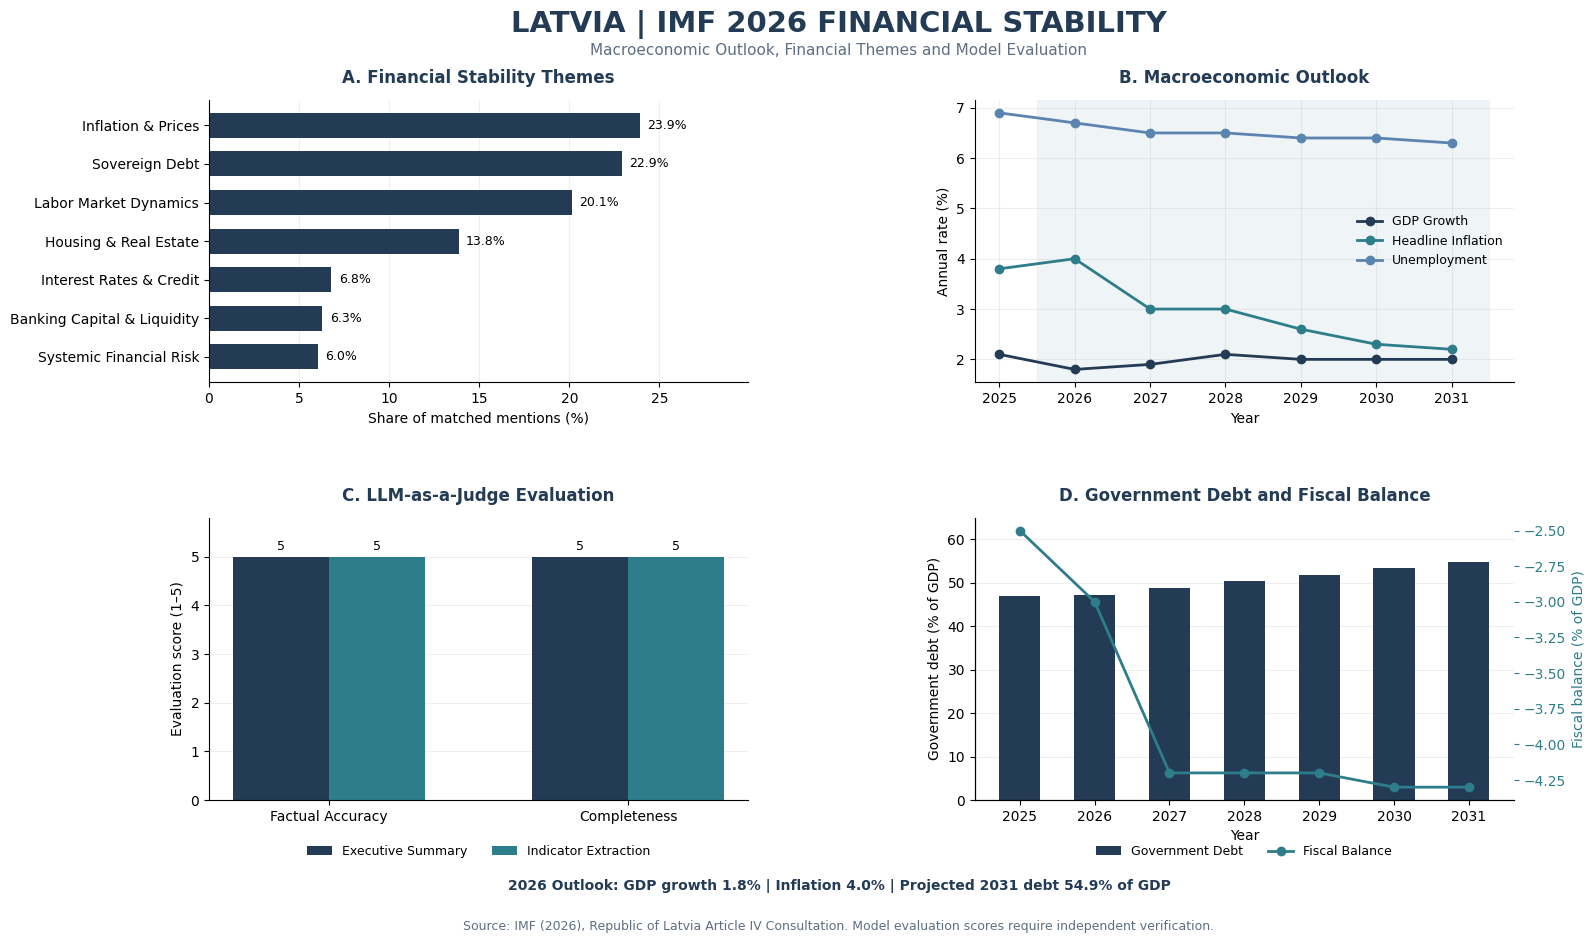

CLEAN DASHBOARD GENERATED
Saved: /content/latvia_task1/latvia_academic_dashboard_clean.png


In [19]:
# Cell 13 with this corrected non-overlapping version

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load data
# --------------------------------------------------
theme_data = load_json("thematic_counts.json")
trend_data = load_json("temporal_trends.json")
summary_eval = load_json("summary_evaluation.json")
indicator_eval = load_json("indicator_evaluation.json")

assert all(x is not None for x in [
    theme_data, trend_data, summary_eval, indicator_eval
]), "Run the previous cells first."

themes = pd.DataFrame(theme_data["themes"])
trends = pd.DataFrame(trend_data["data"]).sort_values("year")

# Required long-format transformation
trend_long = pd.melt(
    trends,
    id_vars="year",
    value_vars=[
        "gdp_growth_pct",
        "inflation_pct",
        "unemployment_pct",
        "government_debt_pct_gdp",
        "fiscal_balance_pct_gdp"
    ],
    var_name="indicator",
    value_name="value"
)

trend_long.to_csv(OUTPUT_DIR / "dashboard_data.csv", index=False)

# --------------------------------------------------
# 2. Style
# --------------------------------------------------
navy = "#233B55"
teal = "#2E7D8A"
blue = "#5B84B1"
grey = "#5F6F82"
light = "#EEF3F7"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

# --------------------------------------------------
# 3. Figure and layout
# --------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

fig.subplots_adjust(
    left=0.08,
    right=0.95,
    top=0.86,
    bottom=0.16,
    wspace=0.42,
    hspace=0.48
)

fig.suptitle(
    "LATVIA | IMF 2026 FINANCIAL STABILITY",
    fontsize=21,
    fontweight="bold",
    color=navy,
    y=0.95
)

fig.text(
    0.5, 0.905,
    "Macroeconomic Outlook, Financial Themes and Model Evaluation",
    ha="center",
    fontsize=11,
    color=grey
)

# --------------------------------------------------
# A. Financial Stability Themes
# --------------------------------------------------
ax = axes[0, 0]

theme_plot = themes.sort_values("percentage")

bars = ax.barh(
    theme_plot["theme"],
    theme_plot["percentage"],
    color=navy,
    height=0.65
)

for bar, pct in zip(bars, theme_plot["percentage"]):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        fontsize=9
    )

ax.set_title("A. Financial Stability Themes", fontweight="bold", color=navy, pad=12)
ax.set_xlabel("Share of matched mentions (%)")
ax.set_xlim(0, theme_plot["percentage"].max() + 6)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# --------------------------------------------------
# B. Macroeconomic Outlook
# --------------------------------------------------
ax = axes[0, 1]

ax.axvspan(2025.5, 2031.5, color=light, alpha=0.9)

ax.plot(
    trends["year"], trends["gdp_growth_pct"],
    marker="o", linewidth=2, color=navy, label="GDP Growth"
)
ax.plot(
    trends["year"], trends["inflation_pct"],
    marker="o", linewidth=2, color=teal, label="Headline Inflation"
)
ax.plot(
    trends["year"], trends["unemployment_pct"],
    marker="o", linewidth=2, color=blue, label="Unemployment"
)

ax.set_title("B. Macroeconomic Outlook", fontweight="bold", color=navy, pad=12)
ax.set_xlabel("Year")
ax.set_ylabel("Annual rate (%)")
ax.set_xticks(trends["year"])
ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=9, loc="center right")

# --------------------------------------------------
# C. LLM-as-a-Judge Evaluation
# --------------------------------------------------
ax = axes[1, 0]

criteria = ["Factual Accuracy", "Completeness"]

summary_scores = [
    summary_eval["factual_accuracy"],
    summary_eval["completeness"]
]
indicator_scores = [
    indicator_eval["accuracy_score"],
    indicator_eval["completeness_score"]
]

x = np.arange(len(criteria))
width = 0.32

bars1 = ax.bar(
    x - width / 2, summary_scores, width,
    color=navy, label="Executive Summary"
)
bars2 = ax.bar(
    x + width / 2, indicator_scores, width,
    color=teal, label="Indicator Extraction"
)

ax.bar_label(bars1, padding=3, fontsize=9)
ax.bar_label(bars2, padding=3, fontsize=9)

ax.set_title("C. LLM-as-a-Judge Evaluation", fontweight="bold", color=navy, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(criteria)
ax.set_ylabel("Evaluation score (1–5)")
ax.set_ylim(0, 5.8)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# legend below chart to avoid overlap
ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

# --------------------------------------------------
# D. Government Debt and Fiscal Balance
# --------------------------------------------------
ax = axes[1, 1]

bars = ax.bar(
    trends["year"],
    trends["government_debt_pct_gdp"],
    color=navy,
    width=0.55,
    label="Government Debt"
)

ax.set_title("D. Government Debt and Fiscal Balance", fontweight="bold", color=navy, pad=12)
ax.set_xlabel("Year")
ax.set_ylabel("Government debt (% of GDP)")
ax.set_xticks(trends["year"])
ax.set_ylim(0, 65)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

ax2 = ax.twinx()
ax2.plot(
    trends["year"],
    trends["fiscal_balance_pct_gdp"],
    color=teal,
    marker="o",
    linewidth=2,
    label="Fiscal Balance"
)
ax2.set_ylabel("Fiscal balance (% of GDP)", color=teal)
ax2.tick_params(axis="y", colors=teal)

# combined legend below chart to avoid overlap
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax.legend(
    handles1 + handles2,
    labels1 + labels2,
    frameon=False,
    fontsize=9,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

# --------------------------------------------------
# 4. Bottom insight text
# --------------------------------------------------
row_2026 = trends.loc[trends["year"] == 2026].iloc[0]
row_2031 = trends.loc[trends["year"] == 2031].iloc[0]

insight = (
    f"2026 Outlook: GDP growth {row_2026['gdp_growth_pct']:.1f}% | "
    f"Inflation {row_2026['inflation_pct']:.1f}% | "
    f"Projected 2031 debt {row_2031['government_debt_pct_gdp']:.1f}% of GDP"
)

fig.text(
    0.5, 0.07,
    insight,
    ha="center",
    fontsize=10,
    fontweight="bold",
    color=navy
)

fig.text(
    0.5, 0.03,
    "Source: IMF (2026), Republic of Latvia Article IV Consultation. "
    "Model evaluation scores require independent verification.",
    ha="center",
    fontsize=9,
    color=grey
)

# --------------------------------------------------
# 5. Save figure
# --------------------------------------------------
dashboard_path = OUTPUT_DIR / "latvia_academic_dashboard_clean.png"

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("=" * 50)
print("CLEAN DASHBOARD GENERATED")
print("=" * 50)
print("Saved:", dashboard_path)

Completed: What financial stability risks arise from nonbank lending in Latvia?
Completed: What fiscal consolidation strategy does the IMF recommend?
Completed: How do energy shocks affect Latvia's inflation and growth?


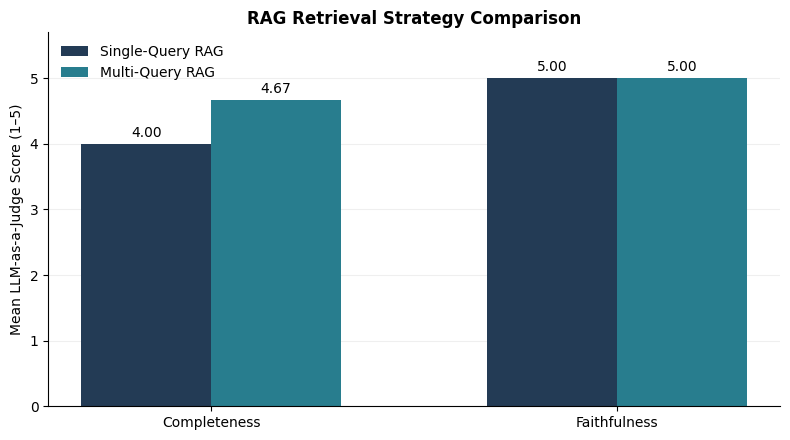


EXTRA CREDIT — BENCHMARK RESULTS
-----------------------------------------------------------------
 Question  Baseline Completeness  Multi-Query Completeness  Baseline Faithfulness  Multi-Query Faithfulness
        1                      5                         4                      5                         5
        2                      3                         5                      5                         5
        3                      4                         5                      5                         5
Completeness difference: +0.67 points
Faithfulness difference: +0.00 points

Saved: multi_query_benchmark.json
Saved: rag_benchmark.csv
Saved: rag_benchmark.png


In [20]:

# CELL 14 — EXTRA CREDIT: MULTI-QUERY RAG BENCHMARKING

# 1. Financial questions for retrieval evaluation
questions = [
    "What financial stability risks arise from nonbank lending in Latvia?",
    "What fiscal consolidation strategy does the IMF recommend?",
    "How do energy shocks affect Latvia's inflation and growth?"
]

# Generate alternative search queries using financial terminology
synonyms = {
    "nonbank lending": "nonbank consumer credit supervision macroprudential risks",
    "fiscal consolidation": "public debt fiscal adjustment revenue spending pressures",
    "energy shocks": "oil gas supply disruptions inflation growth outlook"
}

def expand_queries(question):
    queries = [question]
    for term, alternative in synonyms.items():
        if term in question.lower():
            queries.append(alternative)
    queries.append("Latvia IMF policy risks " + question)
    return list(dict.fromkeys(queries))


# 2. Multi-query retrieval using Reciprocal Rank Fusion
def multi_query_retrieve(question, top_k=5):
    candidates = {}

    for query in expand_queries(question):
        for rank, item in enumerate(rag_retrieve(query, top_k), 1):
            cid = item["chunk_id"]

            if cid not in candidates:
                candidates[cid] = {"item": item, "score": 0}

            candidates[cid]["score"] += 1 / (60 + rank)

    ranked = sorted(
        candidates.values(),
        key=lambda x: x["score"],
        reverse=True
    )

    return [x["item"] for x in ranked[:top_k]]


# 3. Generate answers using retrieved IMF evidence
def grounded_answer(question, passages):
    context = "\n\n".join(
        f"[PDF page {p['page']}] {p['text']}"
        for p in passages
    )

    return generate(
        f"""Answer the question using ONLY this IMF evidence.
Give a concise financial explanation and cite PDF pages.
If the evidence is insufficient, say so.
Do not invent information.

QUESTION: {question}

EVIDENCE:
{context}""",
        max_tokens=400
    )


# 4. Evaluate both answers against identical source evidence
def compare_answers(question, baseline, enhanced, evidence):
    reference = "\n\n".join(
        f"[PDF page {p['page']}] {p['text']}"
        for p in evidence
    )

    prompt = f"""
You are an impartial IMF financial analysis evaluator.

Evaluate TWO answers independently against the same
original IMF source evidence.

Score each answer from 1 to 5 for:
- Completeness: coverage of relevant financial findings.
- Faithfulness: factual consistency with the IMF evidence.

Penalise unsupported statements, incorrect figures,
missing risks and misleading interpretations.
Do not favour either retrieval method.

Return valid JSON with this structure:
{{
  "baseline": {{
    "completeness": 1,
    "faithfulness": 1
  }},
  "multi_query": {{
    "completeness": 1,
    "faithfulness": 1
  }},
  "assessment": "Brief evidence-based comparison"
}}

REFERENCE EVIDENCE:
{reference}

ANSWER A:
{baseline}

ANSWER B:
{enhanced}
"""

    response = client.models.generate_content(
        model=MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(
            temperature=0,
            max_output_tokens=900,
            response_mime_type="application/json"
        )
    )

    result = json.loads(response.text)

    for method in ("baseline", "multi_query"):
        for metric in ("completeness", "faithfulness"):
            value = result[method][metric]
            if type(value) is not int or not 1 <= value <= 5:
                raise ValueError(f"Invalid judge score: {method}/{metric}")

    return result


# 5. Run and cache the benchmark
benchmark = load_json("multi_query_benchmark.json", {})
runs = benchmark.get("runs", {})

rag_version = load_json("rag_metadata.json", {}).get("source_hash", "")
benchmark_key = hashlib.sha256(
    (MODEL + rag_version + "multi_rag_v1").encode()
).hexdigest()

for question in questions:
    cached = runs.get(question, {})

    if cached.get("benchmark_key") == benchmark_key:
        print("Cached:", question)
        continue

    # Equal context budget: five passages for each method
    baseline_hits = rag_retrieve(question, top_k=5)
    multi_hits = multi_query_retrieve(question, top_k=5)

    baseline_answer = grounded_answer(question, baseline_hits)
    multi_answer = grounded_answer(question, multi_hits)

    # Identical reference evidence for fair comparison
    reference = {
        item["chunk_id"]: item
        for item in baseline_hits + multi_hits
    }

    scores = compare_answers(
        question,
        baseline_answer,
        multi_answer,
        list(reference.values())
    )

    runs[question] = {
        "benchmark_key": benchmark_key,
        "query_variations": expand_queries(question),
        "baseline_pages": sorted(set(p["page"] for p in baseline_hits)),
        "multi_query_pages": sorted(set(p["page"] for p in multi_hits)),
        "baseline_answer": baseline_answer,
        "multi_query_answer": multi_answer,
        "evaluation": scores
    }

    save_json("multi_query_benchmark.json", {"runs": runs})
    print("Completed:", question)


# 6. Calculate comparative performance
rows = []

for question in questions:
    result = runs[question]
    scores = result["evaluation"]

    rows.append({
        "Question": questions.index(question) + 1,
        "Baseline Completeness": scores["baseline"]["completeness"],
        "Multi-Query Completeness": scores["multi_query"]["completeness"],
        "Baseline Faithfulness": scores["baseline"]["faithfulness"],
        "Multi-Query Faithfulness": scores["multi_query"]["faithfulness"]
    })

df_benchmark = pd.DataFrame(rows)

metrics = [
    "Completeness",
    "Faithfulness"
]

baseline_means = [
    df_benchmark[f"Baseline {m}"].mean() for m in metrics
]

multi_means = [
    df_benchmark[f"Multi-Query {m}"].mean() for m in metrics
]

# 7. Save a report-ready comparison chart
fig, ax = plt.subplots(figsize=(8, 4.5))

x = np.arange(len(metrics))
width = 0.32

b1 = ax.bar(
    x - width / 2, baseline_means, width,
    label="Single-Query RAG", color="#233B55"
)
b2 = ax.bar(
    x + width / 2, multi_means, width,
    label="Multi-Query RAG", color="#287D8E"
)

ax.bar_label(b1, fmt="%.2f", padding=3)
ax.bar_label(b2, fmt="%.2f", padding=3)

ax.set_title("RAG Retrieval Strategy Comparison", fontweight="bold")
ax.set_ylabel("Mean LLM-as-a-Judge Score (1–5)")
ax.set_xticks(x, metrics)
ax.set_ylim(0, 5.7)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "rag_benchmark.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

df_benchmark.to_csv(
    OUTPUT_DIR / "rag_benchmark.csv",
    index=False
)

print("\nEXTRA CREDIT — BENCHMARK RESULTS")
print("-" * 65)
print(df_benchmark.to_string(index=False))

for i, metric in enumerate(metrics):
    difference = multi_means[i] - baseline_means[i]
    print(f"{metric} difference: {difference:+.2f} points")

print("\nSaved: multi_query_benchmark.json")
print("Saved: rag_benchmark.csv")
print("Saved: rag_benchmark.png")
